### Required Assignment 5.1: Will the Customer Accept the Coupon?

**Context**

Imagine driving through town and a coupon is delivered to your cell phone for a restaurant near where you are driving. Would you accept that coupon and take a short detour to the restaurant? Would you accept the coupon but use it on a subsequent trip? Would you ignore the coupon entirely? What if the coupon was for a bar instead of a restaurant? What about a coffee house? Would you accept a bar coupon with a minor passenger in the car? What about if it was just you and your partner in the car? Would weather impact the rate of acceptance? What about the time of day?

Obviously, proximity to the business is a factor on whether the coupon is delivered to the driver or not, but what are the factors that determine whether a driver accepts the coupon once it is delivered to them? How would you determine whether a driver is likely to accept a coupon?

**Overview**

The goal of this project is to use what you know about visualizations and probability distributions to distinguish between customers who accepted a driving coupon versus those that did not.

**Data**

This data comes to us from the UCI Machine Learning repository and was collected via a survey on Amazon Mechanical Turk. The survey describes different driving scenarios including the destination, current time, weather, passenger, etc., and then ask the person whether he will accept the coupon if he is the driver. Answers that the user will drive there ‘right away’ or ‘later before the coupon expires’ are labeled as ‘Y = 1’ and answers ‘no, I do not want the coupon’ are labeled as ‘Y = 0’.  There are five different types of coupons -- less expensive restaurants (under \$20), coffee houses, carry out & take away, bar, and more expensive restaurants (\$20 - $50).

**Deliverables**

Your final product should be a brief report that highlights the differences between customers who did and did not accept the coupons.  To explore the data you will utilize your knowledge of plotting, statistical summaries, and visualization using Python. You will publish your findings in a public facing github repository as your first portfolio piece.





### Data Description
Keep in mind that these values mentioned below are average values.

The attributes of this data set include:
1. User attributes
    -  Gender: male, female
    -  Age: below 21, 21 to 25, 26 to 30, etc.
    -  Marital Status: single, married partner, unmarried partner, or widowed
    -  Number of children: 0, 1, or more than 1
    -  Education: high school, bachelors degree, associates degree, or graduate degree
    -  Occupation: architecture & engineering, business & financial, etc.
    -  Annual income: less than \\$12500, \\$12500 - \\$24999, \\$25000 - \\$37499, etc.
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she buys takeaway food: 0, less than 1, 1 to 3, 4 to 8 or greater
    than 8
    -  Number of times that he/she goes to a coffee house: 0, less than 1, 1 to 3, 4 to 8 or
    greater than 8
    -  Number of times that he/she eats at a restaurant with average expense less than \\$20 per
    person: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    

2. Contextual attributes
    - Driving destination: home, work, or no urgent destination
    - Location of user, coupon and destination: we provide a map to show the geographical
    location of the user, destination, and the venue, and we mark the distance between each
    two places with time of driving. The user can see whether the venue is in the same
    direction as the destination.
    - Weather: sunny, rainy, or snowy
    - Temperature: 30F, 55F, or 80F
    - Time: 10AM, 2PM, or 6PM
    - Passenger: alone, partner, kid(s), or friend(s)


3. Coupon attributes
    - time before it expires: 2 hours or one day

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

sns.set_theme(style='whitegrid')
%matplotlib inline

### Problems

Use the prompts below to get started with your data analysis.  

1. Read in the `coupons.csv` file.




In [2]:
data = pd.read_csv('data/coupons.csv')

In [3]:
data.head()

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0


2. Investigate the dataset for missing or problematic data.

In [4]:
# Shape, column types, and missing values
print(data.shape)
data.info()

(12684, 26)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12684 entries, 0 to 12683
Data columns (total 26 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   destination           12684 non-null  object
 1   passanger             12684 non-null  object
 2   weather               12684 non-null  object
 3   temperature           12684 non-null  int64 
 4   time                  12684 non-null  object
 5   coupon                12684 non-null  object
 6   expiration            12684 non-null  object
 7   gender                12684 non-null  object
 8   age                   12684 non-null  object
 9   maritalStatus         12684 non-null  object
 10  has_children          12684 non-null  int64 
 11  education             12684 non-null  object
 12  occupation            12684 non-null  object
 13  income                12684 non-null  object
 14  car                   108 non-null    object
 15  Bar                   12

In [5]:
# Count and percentage of missing values per column (only columns with gaps)
missing = data.isna().sum()
missing_pct = (missing / len(data) * 100).round(2)
pd.DataFrame({'missing': missing, 'pct': missing_pct}).query('missing > 0').sort_values('missing', ascending=False)

,missing,pct
car,12576,99.15
CoffeeHouse,217,1.71
Restaurant20To50,189,1.49
CarryAway,151,1.19
RestaurantLessThan20,130,1.02
Bar,107,0.84


In [6]:
# Distinct values in each categorical column, to check for inconsistent labels
for col in data.select_dtypes('object').columns:
    print(f"{col}: {data[col].unique().tolist()}\n")

destination: ['No Urgent Place', 'Home', 'Work']

passanger: ['Alone', 'Friend(s)', 'Kid(s)', 'Partner']

weather: ['Sunny', 'Rainy', 'Snowy']

time: ['2PM', '10AM', '6PM', '7AM', '10PM']

coupon: ['Restaurant(<20)', 'Coffee House', 'Carry out & Take away', 'Bar', 'Restaurant(20-50)']

expiration: ['1d', '2h']

gender: ['Female', 'Male']

age: ['21', '46', '26', '31', '41', '50plus', '36', 'below21']

maritalStatus: ['Unmarried partner', 'Single', 'Married partner', 'Divorced', 'Widowed']

education: ['Some college - no degree', 'Bachelors degree', 'Associates degree', 'High School Graduate', 'Graduate degree (Masters or Doctorate)', 'Some High School']

occupation: ['Unemployed', 'Architecture & Engineering', 'Student', 'Education&Training&Library', 'Healthcare Support', 'Healthcare Practitioners & Technical', 'Sales & Related', 'Management', 'Arts Design Entertainment Sports & Media', 'Computer & Mathematical', 'Life Physical Social Science', 'Personal Care & Service', 'Community & S

In [7]:
# Constant columns and duplicate rows
print('Unique values in toCoupon_GEQ5min:', data['toCoupon_GEQ5min'].unique())
print('direction_same + direction_opp always equals 1:', (data['direction_same'] + data['direction_opp'] == 1).all())
print('Duplicate rows:', data.duplicated().sum())

Unique values in toCoupon_GEQ5min: [1]
direction_same + direction_opp always equals 1: True
Duplicate rows: 74


**Observations**

- The `car` column is almost entirely empty (12,576 of 12,684 rows, roughly 99%) and cannot support any meaningful analysis.
- The five visit-frequency columns (`Bar`, `CoffeeHouse`, `CarryAway`, `RestaurantLessThan20`, `Restaurant20To50`) each have a small number of missing values, between 107 and 217 rows.
- `toCoupon_GEQ5min` holds the value 1 for every row, so it carries no information. `direction_opp` is simply the complement of `direction_same`.
- There are 74 fully duplicated rows.
- The categorical labels are internally consistent, although several are encoded as short codes (for example `less1`, `1~3`, `gt8` for frequency, and `below21`, `50plus` for age). The column `passanger` is misspelled in the source data; the original name is retained so that the code matches the data dictionary.

3. Decide what to do about your missing data -- drop, replace, other...

In [8]:
# 1. Drop the 'car' column: ~99% missing and not recoverable.
# 2. Drop exact duplicate rows.
# 3. Drop rows missing any visit-frequency value. These are a small share of the data (about 5%),
#    and imputing a frequency (e.g., with the mode) would invent behavior for the respondent,
#    which matters because frequency is central to the questions below.
freq_cols = ['Bar', 'CoffeeHouse', 'CarryAway', 'RestaurantLessThan20', 'Restaurant20To50']

rows_before = len(data)
data = data.drop(columns=['car']).drop_duplicates()
data = data.dropna(subset=freq_cols).reset_index(drop=True)

print(f'Rows before: {rows_before:,}  |  Rows after: {len(data):,}  |  Removed: {rows_before - len(data):,} ({(rows_before - len(data)) / rows_before:.1%})')
print('Remaining missing values:', data.isna().sum().sum())

Rows before: 12,684  |  Rows after: 12,007  |  Removed: 677 (5.3%)
Remaining missing values: 0


The `car` column was removed because nearly every value is missing. Duplicate rows were removed so that no response is counted twice. Rows with a missing visit frequency were dropped rather than imputed: they represent about 5% of the data, and filling them with an assumed frequency would introduce fabricated behavior into the very variables that the bar coupon analysis depends upon. The remaining dataset contains 12,007 complete observations.

4. What proportion of the total observations chose to accept the coupon?



In [9]:
accept_rate = data['Y'].mean()
print(f'Overall acceptance rate: {accept_rate:.2%}')
data['Y'].value_counts(normalize=True).rename({1: 'Accepted', 0: 'Rejected'})

Overall acceptance rate: 56.84%


Y
Accepted    0.568418
Rejected    0.431582
Name: proportion, dtype: float64

Roughly 57% of all coupons offered were accepted, so a slight majority of respondents said they would use the coupon either right away or before it expired.

5. Use a bar plot to visualize the `coupon` column.

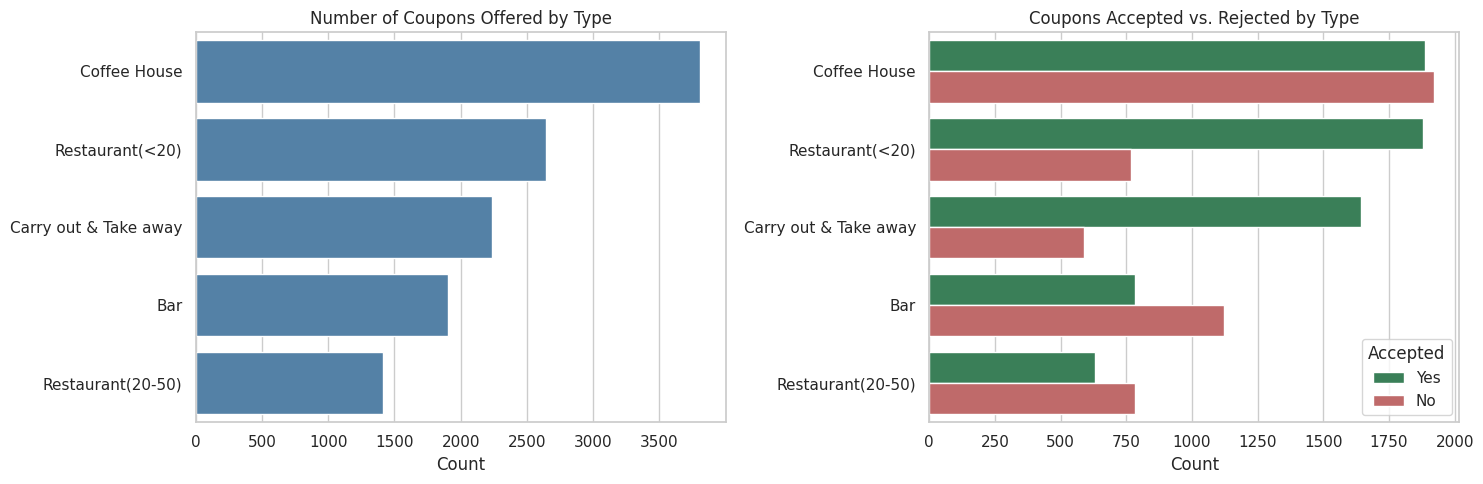

,acceptance_rate,offered
coupon,,
Carry out & Take away,0.736,2233
Restaurant(<20),0.710,2646
Coffee House,0.496,3809
Restaurant(20-50),0.447,1413
Bar,0.412,1906


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

order = data['coupon'].value_counts().index
sns.countplot(data=data, y='coupon', order=order, ax=axes[0], color='steelblue')
axes[0].set_title('Number of Coupons Offered by Type')
axes[0].set_xlabel('Count')
axes[0].set_ylabel('')

sns.countplot(data=data.assign(Accepted=data['Y'].map({1: 'Yes', 0: 'No'})), y='coupon', hue='Accepted',
              hue_order=['Yes', 'No'], order=order, ax=axes[1], palette={'No': 'indianred', 'Yes': 'seagreen'})
axes[1].set_title('Coupons Accepted vs. Rejected by Type')
axes[1].set_xlabel('Count')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

data.groupby('coupon')['Y'].agg(acceptance_rate='mean', offered='size').sort_values('acceptance_rate', ascending=False).round(3)

Coffee House coupons were offered most often, followed by inexpensive restaurants (under \$20). Acceptance varies considerably by coupon type: Carry Out & Take Away (about 74%) and inexpensive restaurant coupons (about 71%) are accepted far more often than Coffee House (about 50%), more expensive restaurant (about 45%), and Bar coupons (about 41%).

6. Use a histogram to visualize the temperature column.

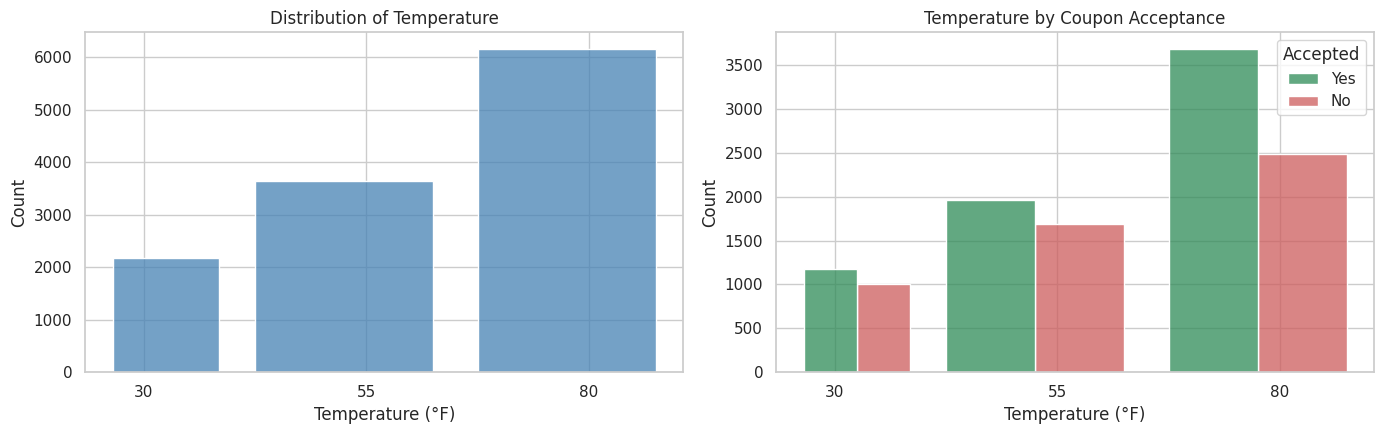

,acceptance_rate,count
temperature,,
30,0.538,2184
55,0.537,3652
80,0.598,6171


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.histplot(data=data, x='temperature', bins=[25, 40, 65, 90], ax=axes[0], color='steelblue', shrink=0.8)
axes[0].set_title('Distribution of Temperature')
axes[0].set_xlabel('Temperature (°F)')
axes[0].set_xticks([30, 55, 80])

sns.histplot(data=data.assign(Accepted=data['Y'].map({1: 'Yes', 0: 'No'})), x='temperature', hue='Accepted',
             hue_order=['Yes', 'No'], multiple='dodge', bins=[25, 40, 65, 90],
             palette={'No': 'indianred', 'Yes': 'seagreen'}, ax=axes[1], shrink=0.8)
axes[1].set_title('Temperature by Coupon Acceptance')
axes[1].set_xlabel('Temperature (°F)')
axes[1].set_xticks([30, 55, 80])

plt.tight_layout()
plt.show()

data.groupby('temperature')['Y'].agg(acceptance_rate='mean', count='size').round(3)

Temperature takes only three values in this survey (30°F, 55°F, and 80°F), and about half of the scenarios occur at 80°F. Acceptance is roughly 54% at both 30°F and 55°F and rises to about 60% at 80°F, which is consistent with drivers being somewhat more willing to make a stop in warm weather.

**Investigating the Bar Coupons**

Now, we will lead you through an exploration of just the bar related coupons.  

1. Create a new `DataFrame` that contains just the bar coupons.


In [12]:
bar = data[data['coupon'] == 'Bar'].copy()
print(bar.shape)
bar.head()

(1906, 25)


,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
2,No Urgent Place,Friend(s),Sunny,80,10AM,Bar,1d,Male,21,Single,...,less1,4~8,4~8,less1,1,0,0,0,1,1
13,Home,Alone,Sunny,55,6PM,Bar,1d,Male,21,Single,...,less1,4~8,4~8,less1,1,0,0,1,0,1
17,Work,Alone,Sunny,55,7AM,Bar,1d,Male,21,Single,...,less1,4~8,4~8,less1,1,1,1,0,1,1
24,No Urgent Place,Friend(s),Sunny,80,10AM,Bar,1d,Male,46,Single,...,4~8,1~3,1~3,never,1,0,0,0,1,0
35,Home,Alone,Sunny,55,6PM,Bar,1d,Male,46,Single,...,4~8,1~3,1~3,never,1,0,0,1,0,0


2. What proportion of bar coupons were accepted?


In [13]:
bar_accept = bar['Y'].mean()
print(f'Bar coupon acceptance rate: {bar_accept:.2%}  (n = {len(bar):,})')

Bar coupon acceptance rate: 41.19%  (n = 1,906)


Approximately 41% of bar coupons were accepted, which is well below the 57% acceptance rate across all coupon types.

3. Compare the acceptance rate between those who went to a bar 3 or fewer times a month to those who went more.


In [14]:
# Helper used for every comparison below
def compare(df, mask, label_in, label_out='All others'):
    """Return the acceptance rate and group size for the rows inside and outside a boolean mask."""
    return pd.DataFrame({
        'acceptance_rate': [df.loc[mask, 'Y'].mean(), df.loc[~mask, 'Y'].mean()],
        'n': [mask.sum(), (~mask).sum()]
    }, index=[label_in, label_out]).round(3)

three_or_fewer = bar['Bar'].isin(['never', 'less1', '1~3'])
compare(bar, three_or_fewer, 'Bar 3 or fewer times/month', 'Bar more than 3 times/month')

,acceptance_rate,n
Bar 3 or fewer times/month,0.372,1713
Bar more than 3 times/month,0.762,193


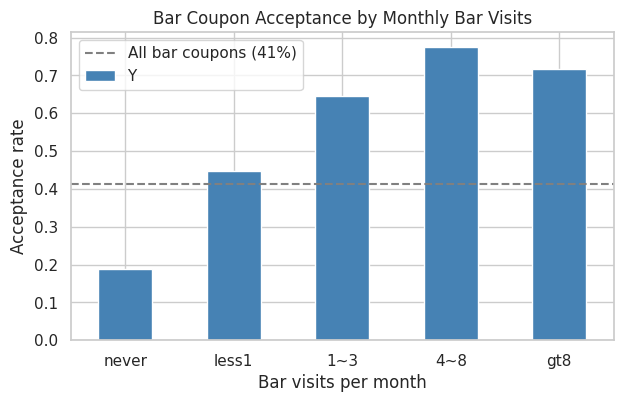

In [15]:
rates = bar.groupby('Bar')['Y'].mean().reindex(['never', 'less1', '1~3', '4~8', 'gt8'])
ax = rates.plot(kind='bar', color='steelblue', figsize=(7, 4), rot=0)
ax.axhline(bar_accept, color='gray', linestyle='--', label=f'All bar coupons ({bar_accept:.0%})')
ax.set_title('Bar Coupon Acceptance by Monthly Bar Visits')
ax.set_xlabel('Bar visits per month')
ax.set_ylabel('Acceptance rate')
ax.legend()
plt.show()

Drivers who go to a bar more than three times a month accepted bar coupons about 76% of the time, roughly double the 37% rate among drivers who go three or fewer times. The chart shows that acceptance rises steadily with bar visit frequency, and that drivers who never go to bars almost never accept the coupon.

4. Compare the acceptance rate between drivers who go to a bar more than once a month and are over the age of 25 to the all others.  Is there a difference?


In [16]:
more_than_once = bar['Bar'].isin(['1~3', '4~8', 'gt8'])
over_25 = ~bar['age'].isin(['below21', '21'])

compare(bar, more_than_once & over_25, 'Bar >1/month AND over 25')

,acceptance_rate,n
Bar >1/month AND over 25,0.690,403
All others,0.337,1503


Yes, there is a substantial difference. Drivers over 25 who go to a bar more than once a month accepted about 69% of bar coupons, compared with about 34% for all other drivers.

5. Use the same process to compare the acceptance rate between drivers who go to bars more than once a month and had passengers that were not a kid and had occupations other than farming, fishing, or forestry.


In [17]:
no_kids = bar['passanger'] != 'Kid(s)'
not_farming = bar['occupation'] != 'Farming Fishing & Forestry'

compare(bar, more_than_once & no_kids & not_farming, 'Bar >1/month, no kid passengers, not farming/fishing/forestry')

,acceptance_rate,n
"Bar >1/month, no kid passengers, not farming/fishing/forestry",0.709,530
All others,0.297,1376


This group accepted about 71% of bar coupons, compared with about 30% for everyone else. The occupation filter removes very few drivers, so most of the effect comes from bar frequency and the absence of children in the car.

6. Compare the acceptance rates between those drivers who:

- go to bars more than once a month, had passengers that were not a kid, and were not widowed *OR*
- go to bars more than once a month and are under the age of 30 *OR*
- go to cheap restaurants more than 4 times a month and income is less than 50K.



In [18]:
not_widowed = bar['maritalStatus'] != 'Widowed'
under_30 = bar['age'].isin(['below21', '21', '26'])
cheap_rest_4plus = bar['RestaurantLessThan20'].isin(['4~8', 'gt8'])
income_under_50k = bar['income'].isin(['Less than $12500', '$12500 - $24999', '$25000 - $37499', '$37500 - $49999'])

cond_a = more_than_once & no_kids & not_widowed
cond_b = more_than_once & under_30
cond_c = cheap_rest_4plus & income_under_50k

pd.concat([
    compare(bar, cond_a, 'A: Bar >1/month, no kid passengers, not widowed').iloc[[0]],
    compare(bar, cond_b, 'B: Bar >1/month, under 30').iloc[[0]],
    compare(bar, cond_c, 'C: Cheap restaurants 4+/month, income < $50K').iloc[[0]],
    compare(bar, cond_a | cond_b | cond_c, 'A OR B OR C')
])

,acceptance_rate,n
"A: Bar >1/month, no kid passengers, not widowed",0.709,530
"B: Bar >1/month, under 30",0.720,328
"C: Cheap restaurants 4+/month, income < $50K",0.456,333
A OR B OR C,0.587,746
All others,0.299,1160


Conditions A and B each produce acceptance rates of roughly 71-72%, while condition C produces only about 46%, which is close to the overall bar coupon rate of 41%. Frequent visits to inexpensive restaurants combined with a lower income is therefore a weak signal on its own. Drivers meeting any of the three conditions accepted about 59% of coupons, compared with about 30% for drivers meeting none of them.

7.  Based on these observations, what do you hypothesize about drivers who accepted the bar coupons?

**Hypothesis**

The strongest single predictor of bar coupon acceptance is how often the driver already goes to bars. Drivers who visit a bar at least once a month accept the coupon at roughly twice the rate of those who rarely or never go, and this holds regardless of how the remaining filters are applied. Within that group, acceptance is further supported by the absence of children in the car and by the driver being a younger adult (under 30) or simply over the legal drinking age. Income and inexpensive-restaurant habits add little. In short, the bar coupon appears to be accepted by drivers who already have an established bar habit and who are in a social context that permits a bar visit; the coupon is unlikely to create new bar-goers.

### Independent Investigation: Coffee House Coupons

Coffee House coupons were selected for this investigation because they are the most frequently offered coupon type (3,809 offers after cleaning) and have an acceptance rate of almost exactly 50%. That even split makes them the coupon for which identifying the accepting customer would be most valuable.

In [19]:
coffee = data[data['coupon'] == 'Coffee House'].copy()
coffee_accept = coffee['Y'].mean()
print(f'Coffee House coupon acceptance rate: {coffee_accept:.2%}  (n = {len(coffee):,})')

Coffee House coupon acceptance rate: 49.57%  (n = 3,809)


**Acceptance by individual attribute**

The function below computes the acceptance rate for each value of a feature, and the plots compare those rates with the overall Coffee House rate (the dashed line).

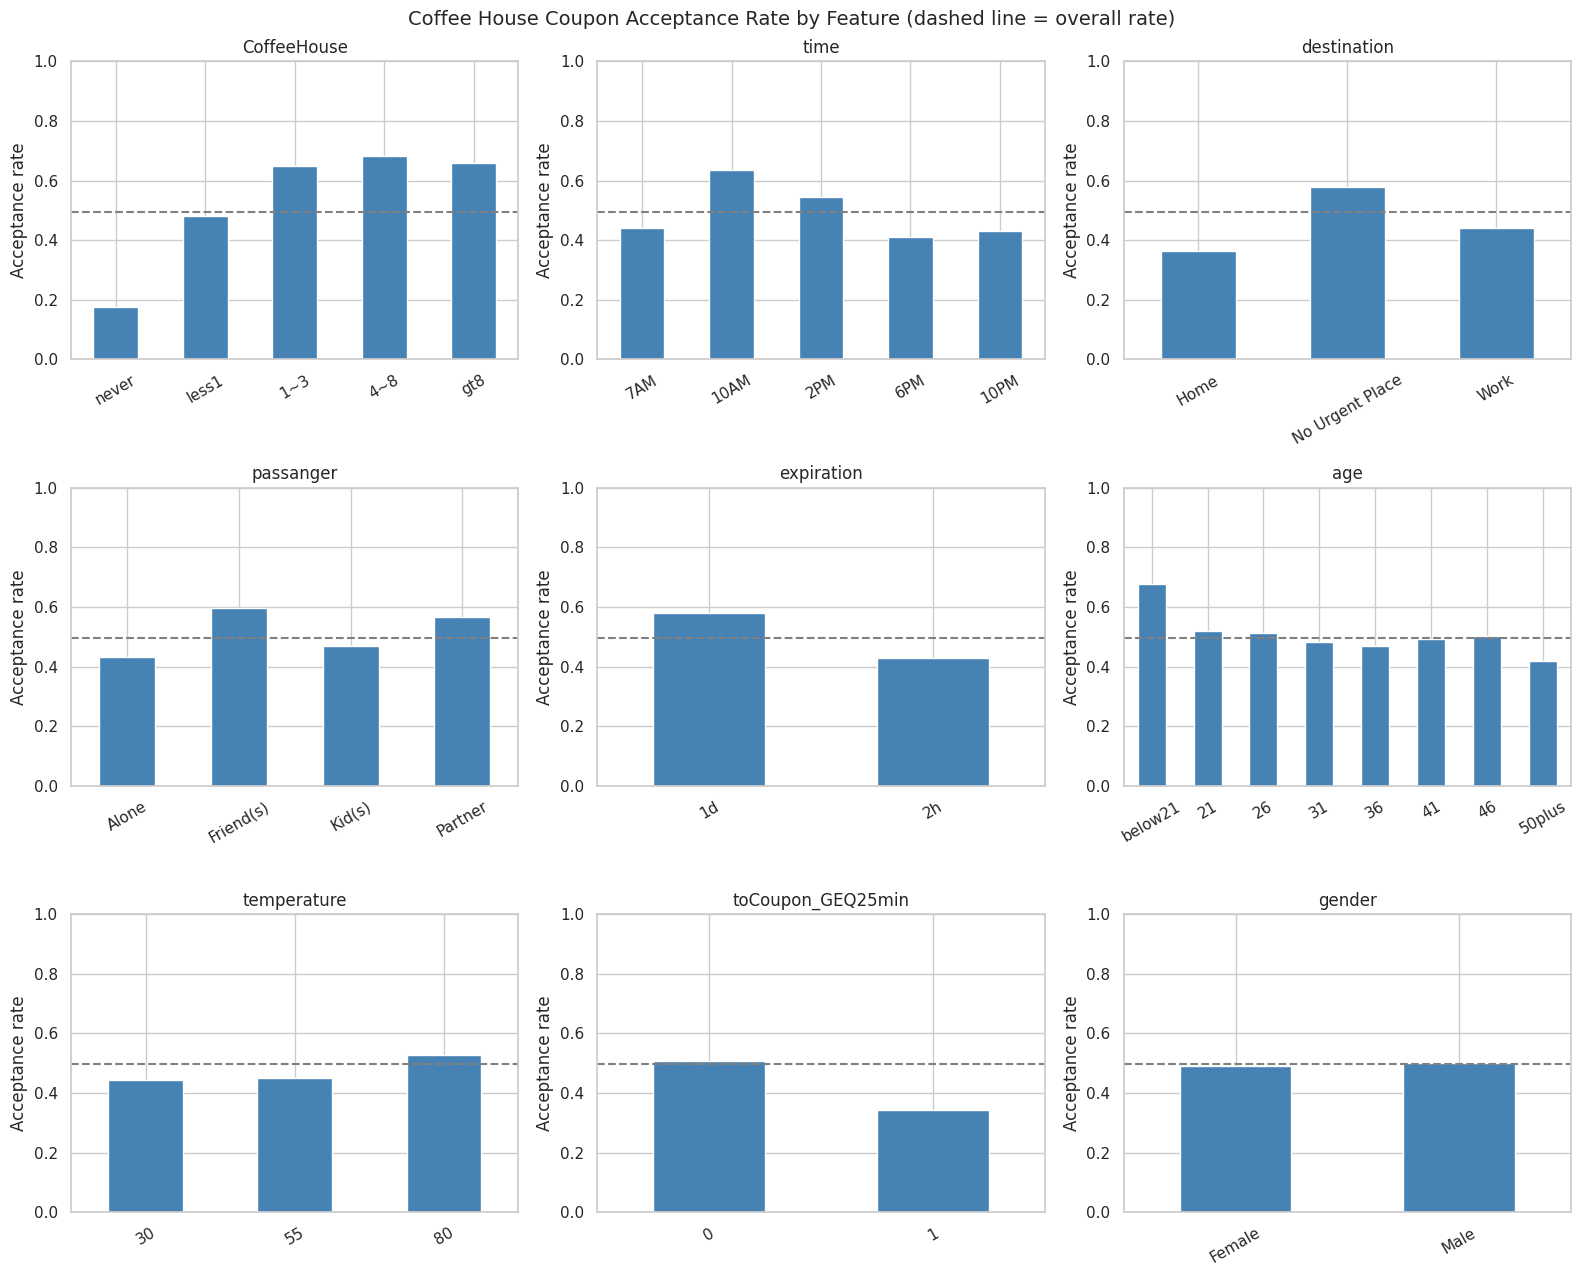

In [20]:
def rate_plot(df, col, order=None, ax=None, baseline=None):
    """Plot the acceptance rate for each value of col, with the baseline rate as a dashed line."""
    rates = df.groupby(col)['Y'].mean()
    if order is not None:
        rates = rates.reindex(order)
    rates.plot(kind='bar', ax=ax, color='steelblue', rot=30)
    if baseline is not None:
        ax.axhline(baseline, color='gray', linestyle='--')
    ax.set_title(col)
    ax.set_xlabel('')
    ax.set_ylim(0, 1)

features = {
    'CoffeeHouse': ['never', 'less1', '1~3', '4~8', 'gt8'],
    'time': ['7AM', '10AM', '2PM', '6PM', '10PM'],
    'destination': None,
    'passanger': None,
    'expiration': None,
    'age': ['below21', '21', '26', '31', '36', '41', '46', '50plus'],
    'temperature': None,
    'toCoupon_GEQ25min': None,
    'gender': None,
}

fig, axes = plt.subplots(3, 3, figsize=(16, 13))
for ax, (col, order) in zip(axes.flat, features.items()):
    rate_plot(coffee, col, order, ax=ax, baseline=coffee_accept)
    ax.set_ylabel('Acceptance rate')
fig.suptitle('Coffee House Coupon Acceptance Rate by Feature (dashed line = overall rate)', fontsize=14)
plt.tight_layout()
plt.show()

In [21]:
summary = []
for col in ['CoffeeHouse', 'time', 'destination', 'passanger', 'expiration', 'age', 'temperature', 'toCoupon_GEQ25min', 'gender']:
    g = coffee.groupby(col)['Y'].agg(['mean', 'size'])
    summary.append({'feature': col,
                    'lowest': f"{g['mean'].idxmin()} ({g['mean'].min():.0%})",
                    'highest': f"{g['mean'].idxmax()} ({g['mean'].max():.0%})",
                    'spread': round(g['mean'].max() - g['mean'].min(), 3)})
pd.DataFrame(summary).sort_values('spread', ascending=False).reset_index(drop=True)

,feature,lowest,highest,spread
0,CoffeeHouse,never (18%),4~8 (68%),0.507
1,age,50plus (42%),below21 (68%),0.259
2,time,6PM (41%),10AM (63%),0.224
3,destination,Home (36%),No Urgent Place (58%),0.215
4,toCoupon_GEQ25min,1 (34%),0 (51%),0.166
5,passanger,Alone (43%),Friend(s) (60%),0.163
6,expiration,2h (43%),1d (58%),0.151
7,temperature,30 (44%),80 (53%),0.083
8,gender,Female (49%),Male (50%),0.011


**Observations**

- **Coffee house visit frequency** is by far the strongest factor. Drivers who never go to coffee houses accepted only about 18% of these coupons, while drivers who go at least once a month accepted roughly 65-68%.
- **Time of day** matters: acceptance peaks at 10AM (about 63%) and falls to about 41-44% at 7AM, 6PM, and 10PM. Mid-morning and early afternoon are natural coffee times, whereas early morning and evening are not.
- **Destination** is closely related: drivers with no urgent destination accepted about 58%, compared with 44% on the way to work and 36% on the way home.
- **Passengers**: drivers with friends (about 60%) or a partner (about 57%) were more receptive than drivers travelling alone (about 43%).
- **Expiration**: coupons valid for one day were accepted about 58% of the time, compared with about 43% for two-hour coupons. A longer window allows the driver to use the coupon on a later trip.
- **Age**: drivers under 21 were the most receptive (about 68%), and drivers 50 and over the least (about 42%).
- **Distance**: when the coffee house is 25 or more minutes away, acceptance drops to about 34%.
- **Gender** shows essentially no difference.

**Interaction between visit frequency and expiration**

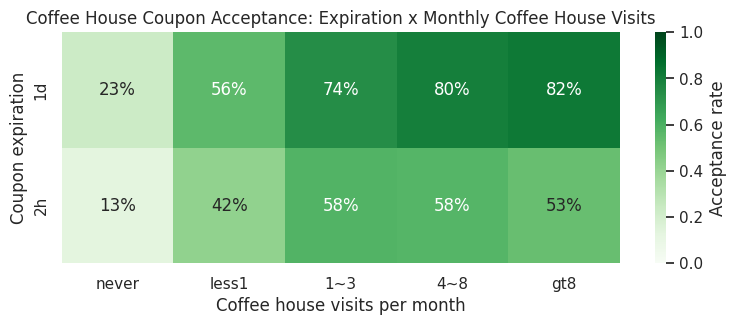

In [22]:
pivot = coffee.pivot_table(index='expiration', columns='CoffeeHouse', values='Y', aggfunc='mean')
pivot = pivot[['never', 'less1', '1~3', '4~8', 'gt8']]

plt.figure(figsize=(9, 3))
sns.heatmap(pivot, annot=True, fmt='.0%', cmap='Greens', vmin=0, vmax=1, cbar_kws={'label': 'Acceptance rate'})
plt.title('Coffee House Coupon Acceptance: Expiration x Monthly Coffee House Visits')
plt.xlabel('Coffee house visits per month')
plt.ylabel('Coupon expiration')
plt.show()

The two effects reinforce one another. Regular coffee house customers holding a one-day coupon accepted 74-82% of the time, while drivers who never visit coffee houses rarely accepted even a one-day coupon (about 23%), and accepted a two-hour coupon only about 13% of the time.

**Combining the strongest factors**

Following the approach used for the bar coupons, the next cell compares drivers who match a combination of the strongest attributes with all other drivers.

In [23]:
regular = coffee['CoffeeHouse'].isin(['1~3', '4~8', 'gt8'])
daytime = coffee['time'].isin(['10AM', '2PM'])
no_urgent = coffee['destination'] == 'No Urgent Place'
with_company = coffee['passanger'] != 'Alone'
one_day = coffee['expiration'] == '1d'

pd.concat([
    compare(coffee, regular, 'Coffee house 1+/month').iloc[[0]],
    compare(coffee, regular & daytime, 'Coffee house 1+/month AND 10AM or 2PM').iloc[[0]],
    compare(coffee, regular & no_urgent & with_company, 'Coffee house 1+/month, no urgent destination, with passengers').iloc[[0]],
    compare(coffee, regular & one_day & no_urgent, 'Coffee house 1+/month, 1-day coupon, no urgent destination').iloc[[0]],
    compare(coffee, ~regular, 'Coffee house less than 1/month or never').iloc[[0]],
])

,acceptance_rate,n
Coffee house 1+/month,0.659,1864
Coffee house 1+/month AND 10AM or 2PM,0.772,784
"Coffee house 1+/month, no urgent destination, with passengers",0.752,787
"Coffee house 1+/month, 1-day coupon, no urgent destination",0.802,465
Coffee house less than 1/month or never,0.339,1945


### Findings

**Coffee House coupons.** Drivers who accept Coffee House coupons are, first and foremost, people who already visit coffee houses at least once a month; they accept at roughly 66%, compared with about 34% for infrequent or non-visitors. Acceptance rises further when the coupon arrives at a natural coffee time (10AM or 2PM), when the driver has no urgent destination, when friends or a partner are in the car, and when the coupon remains valid for a full day. Regular customers receiving the coupon mid-morning or early afternoon accepted about 77% of the time. Conversely, drivers who never visit coffee houses, who are commuting home in the evening, or who would need to travel 25 minutes or more are unlikely to accept.

**Across both investigations.** The common thread between the Bar and Coffee House analyses is that a coupon is most effective when it reinforces an existing habit rather than attempting to create a new one. Past visit frequency for the venue is the strongest single predictor in both cases. Context then determines whether that habit can be acted upon: the presence of children suppresses bar acceptance, while time of day, destination, and expiration window shape Coffee House acceptance. Demographic attributes such as gender and income contribute comparatively little.

**Recommendations.**
1. Target coupons primarily at drivers with a demonstrated history of visiting the venue type.
2. For coffee houses, deliver coupons mid-morning or early afternoon to drivers with no urgent destination, and prefer a one-day expiration over two hours.
3. For bars, avoid sending coupons when children are passengers, and focus on regular bar-goers over the age of 21.
4. Avoid spending coupon inventory on drivers who never visit the venue type, as their acceptance rates are consistently low.